# Logistic regression: NLR, CRP and heart disease

- ive used all 4,544 people not only the training set because its not a prediction but a meassurement.


In [86]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor

# load the shared, cleaned data
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "prepare_data.py").exists())
sys.path.insert(0, str(ROOT))
from prepare_data import load_data

df = load_data()
print(len(df), "people,", int(df["chd_mi"].sum()), "with heart disease")

4544 people, 337 with heart disease


## 1.  Both markers on the same scale

NLR and CRP have different units. We take the log and rescale so that
**1 step = 1 standard deviation (SD)**, a typical difference between two people.

In [87]:
for marker in ["nlr", "crp"]:
    log_values = df[f"log_{marker}"]
    df[f"{marker}_per_sd"] = (log_values - log_values.mean()) / log_values.std()
    print(f"1 SD step = {marker.upper()} about {np.exp(log_values.std()):.1f} times higher")

1 SD step = NLR about 1.6 times higher
1 SD step = CRP about 3.2 times higher


## 2. The three models

Each model adds variables. If OR gets smaller -> part of the link was really due to what we added.
- **Model 1:** age, sex
- **Model 2:** + BMI, ethnicity, income, smoking, diabetes, high blood pressure, cholesterol, HDL, kidney function
- **Model 3:** + cholesterol medication

In [88]:
MODEL_1 = "age + male"
MODEL_2 = MODEL_1 + (" + bmi + C(race_eth, Treatment('nh_white')) + income_pir"
                     " + C(smoking, Treatment('never')) + diabetes"
                     " + hypertension + total_chol + hdl_chol + egfr")
MODEL_3 = MODEL_2 + " + lipid_med"

MODELS = {"Model 1": MODEL_1, "Model 2": MODEL_2, "Model 3": MODEL_3}

## 3. Fit the models

One logistic regression per marker and model (6 in total). We keep the marker's OR, its 95% CI and p-value.
`np.exp(...)` turns the model's raw numbers into odds ratios.

In [89]:
table_2 = pd.DataFrame(index=["NLR", "hs-CRP"], columns=list(MODELS))
p_values = pd.DataFrame(index=["NLR", "hs-CRP"], columns=list(MODELS))
results = []   # the same numbers again, for the plot below

for marker, name in [("nlr", "NLR"), ("crp", "hs-CRP")]:
    for model_name, variables in MODELS.items():
        model = smf.logit(f"chd_mi ~ {marker}_per_sd + {variables}", data=df).fit(disp=0)

        odds_ratio = np.exp(model.params[f"{marker}_per_sd"])
        ci_low, ci_high = np.exp(model.conf_int().loc[f"{marker}_per_sd"])
        p = model.pvalues[f"{marker}_per_sd"]

        table_2.loc[name, model_name] = f"{odds_ratio:.2f} ({ci_low:.2f}\u2013{ci_high:.2f})"
        p_values.loc[name, model_name] = "<0.001" if p < 0.001 else f"{p:.3f}"
        results.append({"marker": name, "model": model_name, "OR": odds_ratio, "low": ci_low, "high": ci_high})

print("Table 2: odds ratio (95% CI) per 1 SD")
display(table_2)
print("p-values")
display(p_values)

Table 2: odds ratio (95% CI) per 1 SD


,Model 1,Model 2,Model 3
NLR,1.26 (1.13–1.42),1.18 (1.04–1.34),1.18 (1.04–1.34)
hs-CRP,1.14 (1.01–1.29),0.96 (0.83–1.11),1.01 (0.88–1.17)


p-values


,Model 1,Model 2,Model 3
NLR,<0.001,0.010,0.011
hs-CRP,0.039,0.585,0.878


### Forest plot of Table 2

Dot = odds ratio, line = 95% CI. The dashed line is OR = 1 (no link). If a line crosses it, the link is not clear.

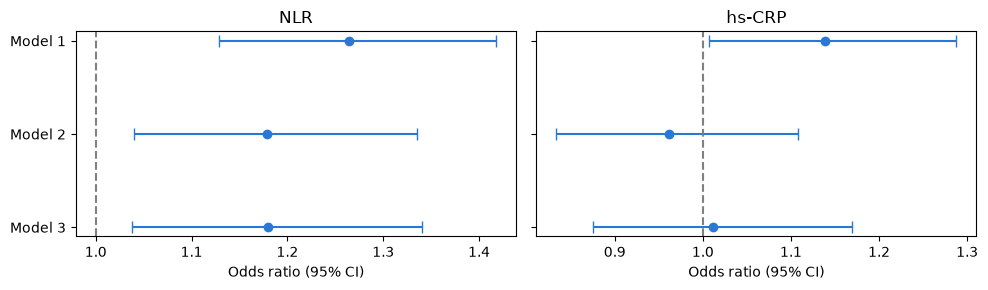

In [90]:
results = pd.DataFrame(results)

fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
for ax, name in zip(axes, ["NLR", "hs-CRP"]):
    rows = results[results["marker"] == name]
    ax.errorbar(rows["OR"], rows["model"], xerr=[rows["OR"] - rows["low"], rows["high"] - rows["OR"]],
                fmt="o", color="#2a78d6", capsize=4)
    ax.axvline(1, color="grey", linestyle="--")   # OR = 1: no link
    ax.set_title(name)
    ax.set_xlabel("Odds ratio (95% CI)")
axes[0].invert_yaxis()                            # Model 1 on top
plt.tight_layout()
plt.show()

## 4. Two checks

1. **Is a straight line OK?** The model assumes every step up in a marker adds the same amount of risk.
   We compare it with a curve that is allowed to bend. p above 0.05 = the straight line is fine.
2. **Are two variables too similar?** Then the model can't tell them apart.
   The VIF measures this: below 5 = fine.

In [91]:
# Check 1: straight line vs. bendy curve (both with all Model 3 variables)
for marker in ["nlr", "crp"]:
    straight = smf.logit(f"chd_mi ~ log_{marker} + {MODEL_3}", data=df).fit(disp=0)
    curve = smf.logit(f"chd_mi ~ cr(log_{marker}, df=3, constraints='center') + {MODEL_3}", data=df).fit(disp=0)
    # likelihood-ratio test: does the curve fit clearly better than the straight line?
    p = stats.chi2.sf(2 * (curve.llf - straight.llf), curve.df_model - straight.df_model)
    print(f"Straight line for {marker.upper()}: p = {p:.2f}")

# Check 2: VIF of every variable in Model 3
model = smf.logit(f"chd_mi ~ nlr_per_sd + {MODEL_3}", data=df).fit(disp=0)
X = model.model.exog
vif = [variance_inflation_factor(X, i) for i in range(1, X.shape[1])]   # skip column 0 (the intercept)
print(f"Highest VIF: {max(vif):.1f}")

Straight line for NLR: p = 0.27
Straight line for CRP: p = 1.00
Highest VIF: 2.3


## 5. Figure 2: chance of heart disease across marker levels

For each marker value we pretend **everyone** has that value, let Model 3 predict each person's chance of heart disease,
and take the average. So the curve shows the marker's effect with all other variables accounted for.
(No uncertainty band here: for that, look at the CI in Table 2.)

NLR: 5.3% at the low end, 9.5% at the high end
hs-CRP: 7.3% at the low end, 7.6% at the high end


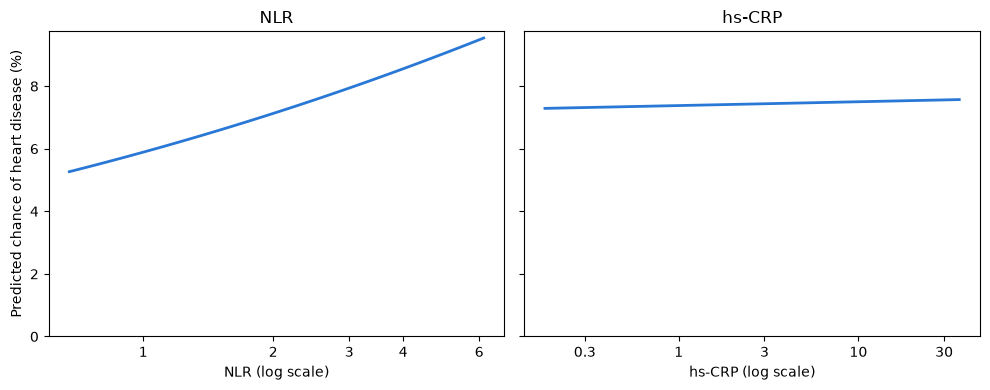

In [92]:
TICKS = {"nlr": [1, 2, 3, 4, 6], "crp": [0.3, 1, 3, 10, 30]}

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, (marker, name) in zip(axes, [("nlr", "NLR"), ("crp", "hs-CRP")]):
    model = smf.logit(f"chd_mi ~ log_{marker} + {MODEL_3}", data=df).fit(disp=0)
    values = np.geomspace(df[marker].quantile(0.01), df[marker].quantile(0.99), 50)   # 1st to 99th percentile

    chance = []
    for value in values:
        everyone = df.copy()
        everyone[f"log_{marker}"] = np.log(value)               # pretend everyone has this value
        chance.append(100 * model.predict(everyone).mean())     # average predicted chance, in %

    ax.plot(values, chance, color="#2a78d6", linewidth=2)
    ax.set_xscale("log")
    ax.set_xticks(TICKS[marker], [str(t) for t in TICKS[marker]])
    ax.minorticks_off()
    ax.set_title(name)
    ax.set_xlabel(f"{name} (log scale)")
    print(f"{name}: {chance[0]:.1f}% at the low end, {chance[-1]:.1f}% at the high end")

axes[0].set_ylabel("Predicted chance of heart disease (%)")
axes[0].set_ylim(0, None)                       # start at 0 so the effect isn't exaggerated
plt.tight_layout()
plt.show()

## 6. Results from the logistic regression



- NLR: yes. Higher NLR goes with more heart disease, even in Model 3 (the one with the statins medication): OR 1.18 (1.04–1.34), p = 0.011. A 1 SD higher NLR means 18% higher odds.

- CRP: no. Once the risk factors are added (in Model 2 and 3), the link is gone: OR 1.01 (0.88–1.17), p = 0.88.

- Model 1 to 2: both ORs get smaller, so part of the link was due to the risk factors. Model 3 (medication) changes almost nothing.

- Checks OK: the straight line is fine (NLR p = 0.27, CRP p = 1.00), and the highest VIF is 2.3.

- -> it only shows a link not a cause 

